# Lab 3 : PCA

## G3 SDI - Machine Learning

In this lab, we are going to study the most fundamental dimensionality reduction method : PCA. More precisely, we are going to apply it to the *Olivetti* dataset, which contains images of faces.

### Instructions
* Rename your notebook with your surnames as `lab3_Name1_Name2.ipynb`, and include your names in the notebook.
* Your code, and its output, must be commented !
* Please upload your notebook on Moodle in the dedicated section before the deadline.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Report written by FERNANDES--STRAG, TORRES--LEGUET, 18/11/26.
</div>

In [1]:
# Import usual libraries
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# Import the dataset
from sklearn.datasets import fetch_olivetti_faces

data = fetch_olivetti_faces()

**Q1.** What is this dataset about ? How many examples do we have ? How many features ?

Display the first 50 images from the dataset. Comment.

In [17]:
print("Taille des images :", data['images'].shape)
print("Valeurs minimales et maximales des pixels :", data.images[0].min(), data.images[0].max())

X = data['images'].reshape(data['images'].shape[0], -1) # matrice des exemples (N, D)
y = data.target # vecteur des labels (N,)

Taille des images : (400, 64, 64)
Valeurs minimales et maximales des pixels : 0.08264463 0.87603307


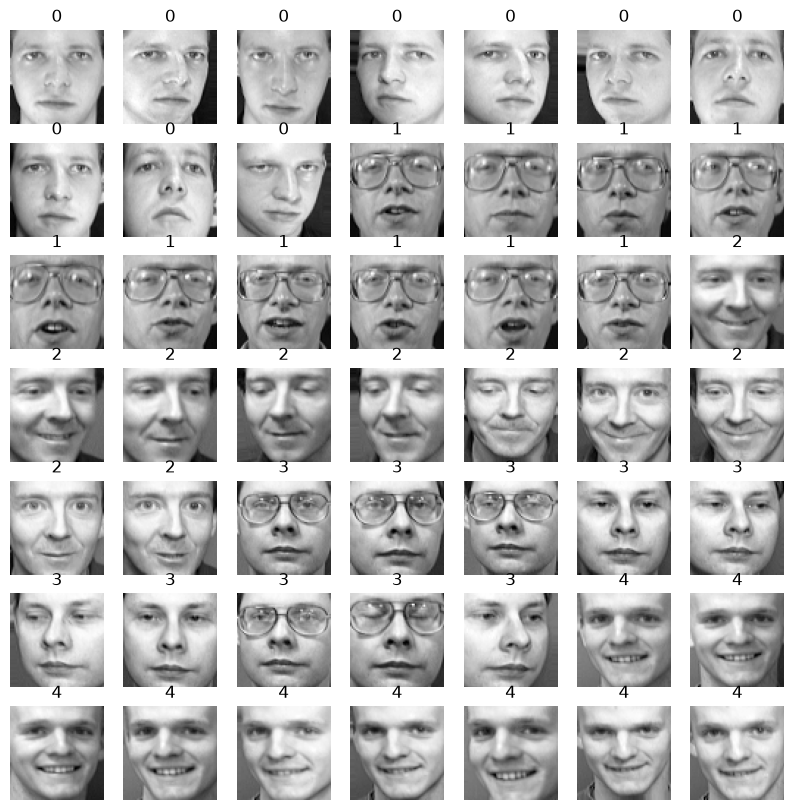

In [18]:
fig, ax = plt.subplots(7, 7, figsize=(10, 10))

for i in range(7):
    for j in range(7):
        ax[i, j].imshow(data['images'][i*7+j], cmap='gray')
        ax[i, j].set_title(data.target[i*7+j])
        ax[i, j].axis('off')

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Le dataset contient des images 64x64 en échelle de gris de visages.

Il y a 400 exemples, bien que la même personne apparaît plusieurs fois sous différents angles (donc certains exemples sont corrélés).

Il y a par image 64*64=4096 pixels, chaque pixel étant encondé par un niveau de gris entre 0 et 1. Il y a donc 4096 caractéristiques, qui valent chacune entre 0 et 1.

Il y a aussi une attribut "target" qui identifie la personne présente sur la photo, qu'on utilisera en Q4. On l'affiche dès à présent ici pour constater qu'on retrouve bien la même personne plus fois.
</div>

**Q2**. Now apply PCA to the dataset, using scikit-learn (documentation [here](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)).

Plot the cumulative explained variance. How many components do we need to explain 95% of the variance ?

In [5]:
from sklearn.decomposition import PCA

# on applique PCA sur X
pca = PCA(n_components=200)
pca.fit(X)

# pca.explained_variance_ratio_ : liste des variances expliquées par chaque composante principale trouvée

print("Variance expliquée par les composantes les plus importantes:")
print(pca.explained_variance_ratio_[:10])

# on calcule ensuite la variance expliquée cumulée, en sommant les variances expliquées par chaque composante principale
explained_variance_cum = np.cumsum(pca.explained_variance_ratio_) # revient à faire x1, x1+x2, x1+x2+x3...

# nombre de composantes principales nécessaires pour expliquer 95% de la variance:
n_95 = np.sum(explained_variance_cum < 0.95) + 1

# np.sum(explained_variance_cum < 0.95) = nombre de composantes pour avoir une variance cumulée juste en dessous de 0.95
# on fait +1 pour passer à >0.95 

print("Nombre de composantes principales nécessaires pour expliquer 95% de la variance : ", n_95)

Variance expliquée par les composantes les plus importantes:
[0.23812726 0.13993962 0.07968616 0.04998337 0.03609853 0.03156943
 0.02426833 0.02036399 0.01958113 0.01672122]
Nombre de composantes principales nécessaires pour expliquer 95% de la variance :  123


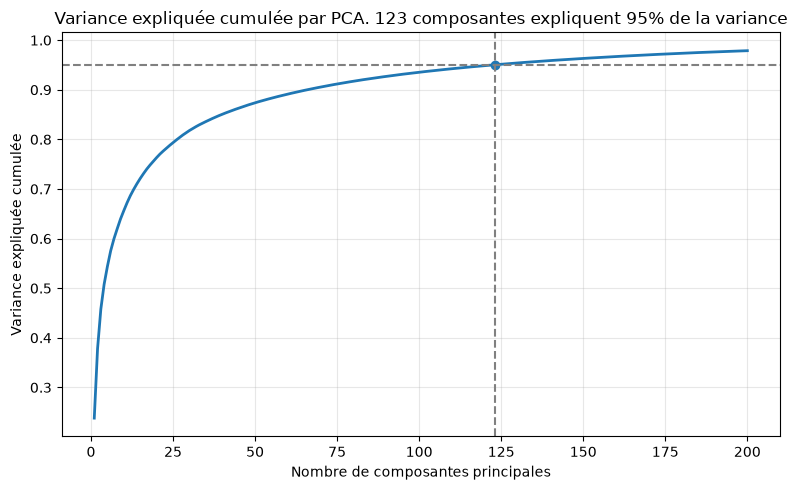

In [6]:
# affichage de la variance expliquée cumulée en fonction du nombre de composantes principales

# axe des abscisses
x = np.arange(1, len(explained_variance_cum) + 1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, explained_variance_cum, lw=2)

ax.axhline(0.95, color="grey", ls="--")
ax.axvline(n_95, color="grey", ls="--")
ax.scatter(n_95, explained_variance_cum[n_95-1])

ax.set_xlabel("Nombre de composantes principales")
ax.set_ylabel("Variance expliquée cumulée")
ax.set_title("Variance expliquée cumulée par PCA. {} composantes expliquent 95% de la variance".format(n_95))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On applique PCA sur nos données. On utilise un nombre de composantes très élevé pour être sûr de capturer plus de 95% de la variance et donc de pouvoir répondre à la question : il faut 123 composantes pour expliquer 95% de la variance des données. Ce nombre reste élevé, bien que cela représente une baisse de x33 de la dimension par rapport aux données pour peu de perte. On note aussi que le nombre de composantes maximales qu'on peut utiliser est borné par 400, le nombre d'exemples, car c'est ici le nombre d'exemples le facteur limitant, et non le nombre de features.

Pour appliquer PCA, les données doivent être centrées, mais après lecture de la documentation, il se trouve que sklearn.decomposition.PCA le fait automatiquement donc nous n'avons pas besoin de le faire.


</div>

**Q3.** Retrieve the principal components. These are the so-called *eigenfaces*. Display the first 40, and comment : what do the main components seem to capture ? What about later components ?

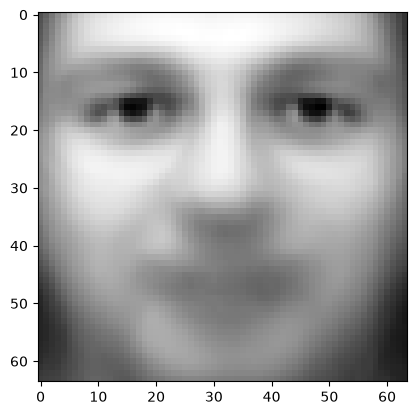

In [7]:
# on visualise le visage moyen :
plt.imshow(np.mean(data['images'], axis=0), cmap='gray')

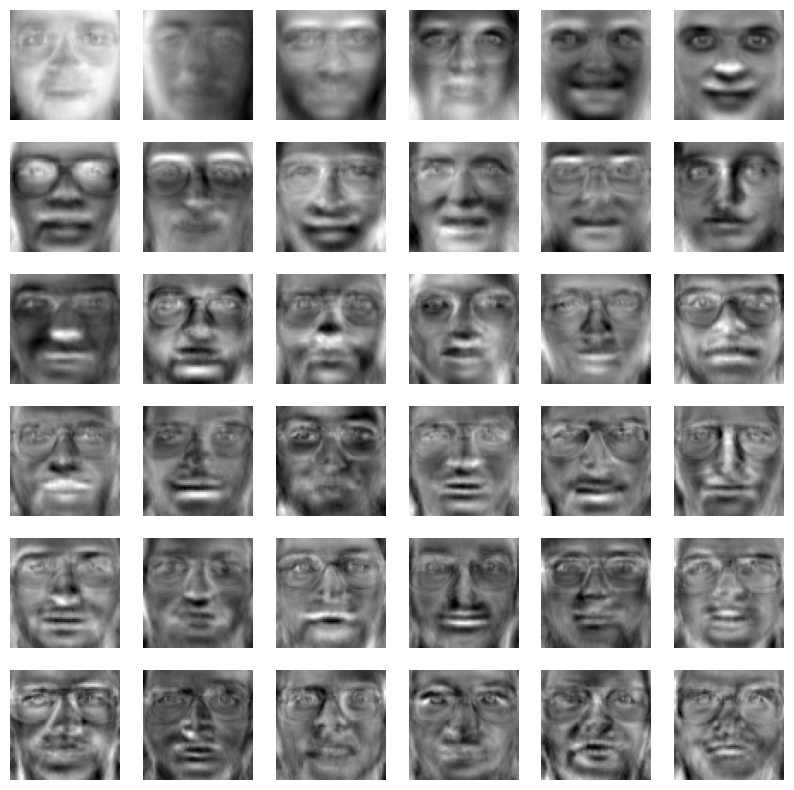

In [8]:
pca.components_.shape

fig, ax = plt.subplots(6, 6, figsize=(10, 10))

for i in range(6):
    for j in range(6):
        ax[i, j].imshow(pca.components_[i*6+j].reshape(64, 64), cmap='gray')
        ax[i, j].axis('off')

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Analyse du visage moyen:

Cette image obtenue en faisant la moyenne des exemples montre les valeurs "par défaut" des 4096 features. C'est donc la base à partir de laquelle on va pouvoir comparer les variances identifiées par chaque composante principale.
La plupart des visages s'accordent sur la présence des yeux, qui sont assez nets dans l'image moyenne. Viennent ensuite le nez et la bouche.

Analyse des composantes principales:

Les composantes de PCA nous montrent les zones de l'image où il y a la plus grande variance, ou encore, les plus grands écarts à l'image moyenne. Les premières composantes montrent des différences sur des zones globales du visage (son exposition à la luminosité, son orientation, la présence de sourcils, la forme de la bouche etc). Les composantes suivantes détectent des changements plus fins comme la présence de lunettes, une forme particulière de nez etc.

</div>

**Q4.** The *Olivetti* dataset contains a target variable, which correspond to the ID of the person in the photo (there are 40 distinct persons).

Compare the cross-validated performance (e.g., 5-fold) of logistic regression on the original dataset vs. on the representation induced by PCA using the first 50 components. Be careful to *stratify* the test set. Comment. You may also take the execution time in consideration in your reply.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# préparation des sets de données
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

# on reprend et modifie le code du lab 1 (Part II Q4) pour la K-fold

# régression logistique complète
kf = StratifiedKFold(n_splits=5)
accs = []
for train_index, val_index in kf.split(X_train, y_train):
    # (les données ont déjà été mélangées lors du train_test_split)
    X_train_fold, X_val_fold = X_train[train_index], X_train[val_index]
    y_train_fold, y_val_fold = y_train[train_index], y_train[val_index]

    scaler = StandardScaler()
    scaler.fit(X_train_fold)
    X_train_fold = scaler.transform(X_train_fold)
    X_val_fold = scaler.transform(X_val_fold)

    model = LogisticRegression()
    model.fit(X_train_fold, y_train_fold)

    accs.append(model.score(X_val_fold, y_val_fold))
    
print("Régression logistique complète")
print("- Accuracy moyenne sur les 5 folds : ", np.mean(accs))

# régression logistique avec les features PCA (50 composantes)
kf = StratifiedKFold(n_splits=5)
accs = []
for train_index, val_index in kf.split(X_train, y_train):
    # (les données ont déjà été mélangées lors du train_test_split)
    X_train_fold, X_val_fold = X_train[train_index], X_train[val_index]
    y_train_fold, y_val_fold = y_train[train_index], y_train[val_index]

    pca = PCA(n_components=50)
    pca.fit(X_train_fold)
    X_pca_train_fold = pca.transform(X_train_fold)
    X_pca_val_fold = pca.transform(X_val_fold) # important : on utilise le PCA fitté sur le train pour transformer le test (comme pour la normalisation)

    scaler = StandardScaler()
    scaler.fit(X_pca_train_fold)
    X_pca_train_fold = scaler.transform(X_pca_train_fold)
    X_pca_val_fold = scaler.transform(X_pca_val_fold)

    model = LogisticRegression()
    model.fit(X_pca_train_fold, y_train_fold)

    accs.append(model.score(X_pca_val_fold, y_val_fold))
    
print("Régression logistique avec les features PCA")
print("- Accuracy moyenne sur les 5 folds : ", np.mean(accs))

Régression logistique complète
- Accuracy moyenne sur les 5 folds :  0.953125
Régression logistique avec les features PCA
- Accuracy moyenne sur les 5 folds :  0.959375


In [11]:
# optimisation du compromis dimension vs performance

# d'un point de vue qualité

n_composantes = [2, 5, 10, 15, 20, 30, 40, 50, 60, 70, 80, 90, 100, 150, 200]
accuracies_composantes = []

for n_c in n_composantes:
    kf = StratifiedKFold(n_splits=5)
    accs = []
    for train_index, val_index in kf.split(X_train, y_train):
        X_train_fold, X_val_fold = X_train[train_index], X_train[val_index]
        y_train_fold, y_val_fold = y_train[train_index], y_train[val_index]

        pca = PCA(n_components=n_c)
        pca.fit(X_train_fold)
        X_pca_train_fold = pca.transform(X_train_fold)
        X_pca_val_fold = pca.transform(X_val_fold) # important : on utilise le PCA fitté sur le train pour transformer le val (comme pour la normalisation)

        scaler = StandardScaler()
        scaler.fit(X_pca_train_fold)
        X_pca_train_fold = scaler.transform(X_pca_train_fold)
        X_pca_val_fold = scaler.transform(X_pca_val_fold)
    
        model = LogisticRegression()
        model.fit(X_pca_train_fold, y_train_fold)

        accs.append(model.score(X_pca_val_fold, y_val_fold))

    accuracies_composantes.append(np.mean(accs))

In [12]:
# d'un point de vue computationnel

def classification_PCA(n_c):
    # PCA
    pca = PCA(n_components=n_c)
    pca.fit(X_train)
    X_pca_train = pca.transform(X_train)
    # normalisation
    scaler = StandardScaler()
    scaler.fit(X_pca_train)
    X_pca_train = scaler.transform(X_pca_train)
    # entraînement
    model = LogisticRegression()
    model.fit(X_pca_train, y_train)

def classification_complete():
    # normalisation
    scaler = StandardScaler()
    scaler.fit(X_train)
    X_train_scaled = scaler.transform(X_train)
    # entraînement
    model = LogisticRegression()
    model.fit(X_train_scaled, y_train)

temps = []
for n_c in n_composantes:
    res = %timeit -o -q -r 3 -n 1 classification_PCA(n_c)
    temps.append(res.average)

res = %timeit -o -q -r 3 -n 1 classification_complete()
print("Temps d'entraînement de la régression logistique complète : ", res.average)

Temps d'entraînement de la régression logistique complète :  0.06361844499285023


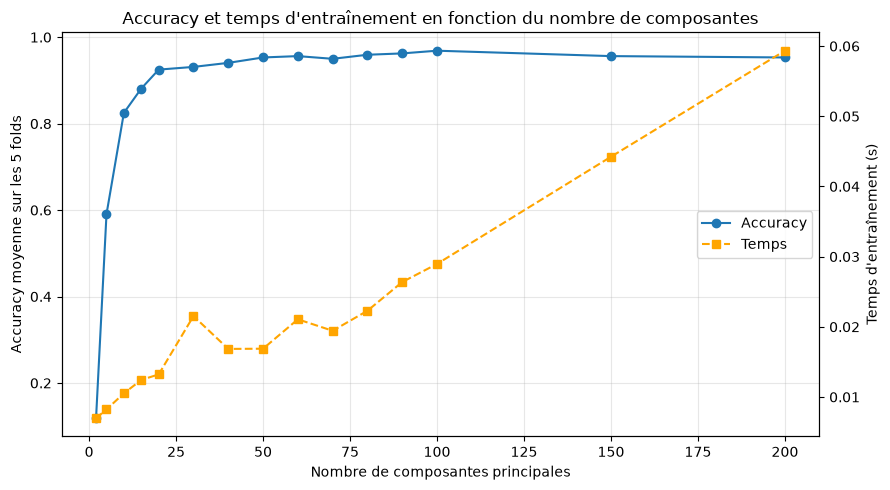

In [13]:
fig, ax1 = plt.subplots(figsize=(9, 5))

# on va montrer sur le même axe :
# accuracy vs composantes
# temps d'entraînement vs composantes

# accuracy axe de gauche
l1 = ax1.plot(n_composantes, accuracies_composantes, marker='o', label="Accuracy")
ax1.set_xlabel("Nombre de composantes principales")
ax1.set_ylabel("Accuracy moyenne sur les 5 folds")
ax1.tick_params(axis='y')

# temps axe de droite
ax2 = ax1.twinx()
l2 = ax2.plot(n_composantes, temps, marker='s', ls='--', color='orange', label="Temps")
ax2.set_ylabel("Temps d'entraînement (s)")

lignes = l1 + l2
ax1.legend(lignes, [l.get_label() for l in lignes], loc='center right')

ax1.set_title("Accuracy et temps d'entraînement en fonction du nombre de composantes")
ax1.grid(alpha=0.3)
plt.tight_layout()
plt.show()


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On compare d'abord la régression logistique sur le dataset complet avec la régression logistique sur le dataset réduit en dimension avec PCA. Les performances sont globalement les mêmes, ce qui montre que la réduction de dimension (de 4096 à 50) ne fait pas perdre l'information qui permet d'identifier les personnes dans l'image. Au contraire même, cela semble aider dans une certaine mesure. On explique celà par un effet de régularisation apportée par la réduction de dimensionnalité, qui empêche le modèle de régression logistique d'apprendre du bruit, et est forcé de se concentrer sur des caractéristiques importantes.

Note 1 : pour respecter l'équilibre entre les classes au sein de chaque fold, on utilise StratifiedKFold, et on fait aussi attention au niveau du split train/test d'également stratifier selon la target via `(stratify=y)`. Le risque de déséquilibrage ici est élevé car on a beaucoup de classes différentes.

Note 2 : on fait attention, dans la procédure par K-fold, à fitter le PCA seulement sur les données d'entraînement pour ce fold, et de re-utiliser ce même PCA fitté sur les données de val pour ce fold. Cela nous oblige à re-fitter un PCA pour chaque fold, mais c'est plus rigoureux. Idem pour la normalisation.

Note 3 : on standarise les données en sortie de PCA. En effet, en sortie de PCA, on sait que les données sont centrées, mais leur écart-type n'est pas de 1. Sur ce cas, cela n'a pas d'effet significatif sur la qualité, mais bien sur la convergence de l'optimiseur L-BFGS. Sans la normalisation, il faut augmenter le nombre d'itérations (de 100 par défaut à 1000) pour converger.

On optimise ensuite le compromis entre réduction de dimension et qualité du modèle.

On regarde pour cela l'évolution de la qualité de prédiction du modèle logistique en fonction du nombre de composantes principales sélectionnées pour le dataset. On observe un plateau atteint autour de 50 composantes. Baisser trop le nombre de dimensions (<25) dégrade rapidement le modèle : on perd l'information qui permettait d'identifier les personnes dans l'image. Dans le cas présent, le risque d'overfit avec la régression linéaire est faible, mais on peut imaginer qu'utiliser PCA peut fortement aider si on utilisait un modèle plus expressif : la réduction de dimension (pas trop forte) aide car agit comme une régularisation. 

On regarde en même temps le temps d'execution de l'entraînement en fonction du nombre de composantes.
En prenant en compte le temps d'execution, <b>le meilleur compromis se trouve autour de 50 composantes</b>.
Dans tous les cas, réduire la dimension des données avec PCA en amont réduit le temps total d'entraînement (environ 4x plus rapide ici : 0.06s -> 0.015s), sans perte de qualité.

</div>

**Q5**. To reconstruct a point back in its original representation, we can use the `.inverse_transform` method.

Since we are working with images, after reducing the dimensionality, we will obtain an imperfect reconstruction of the original image.

Set now the number of components of PCA to 300. Select an image from the dataset, and compare it to its reconstruction. You may assess the quality of the reconstruction with a metric of your choice.

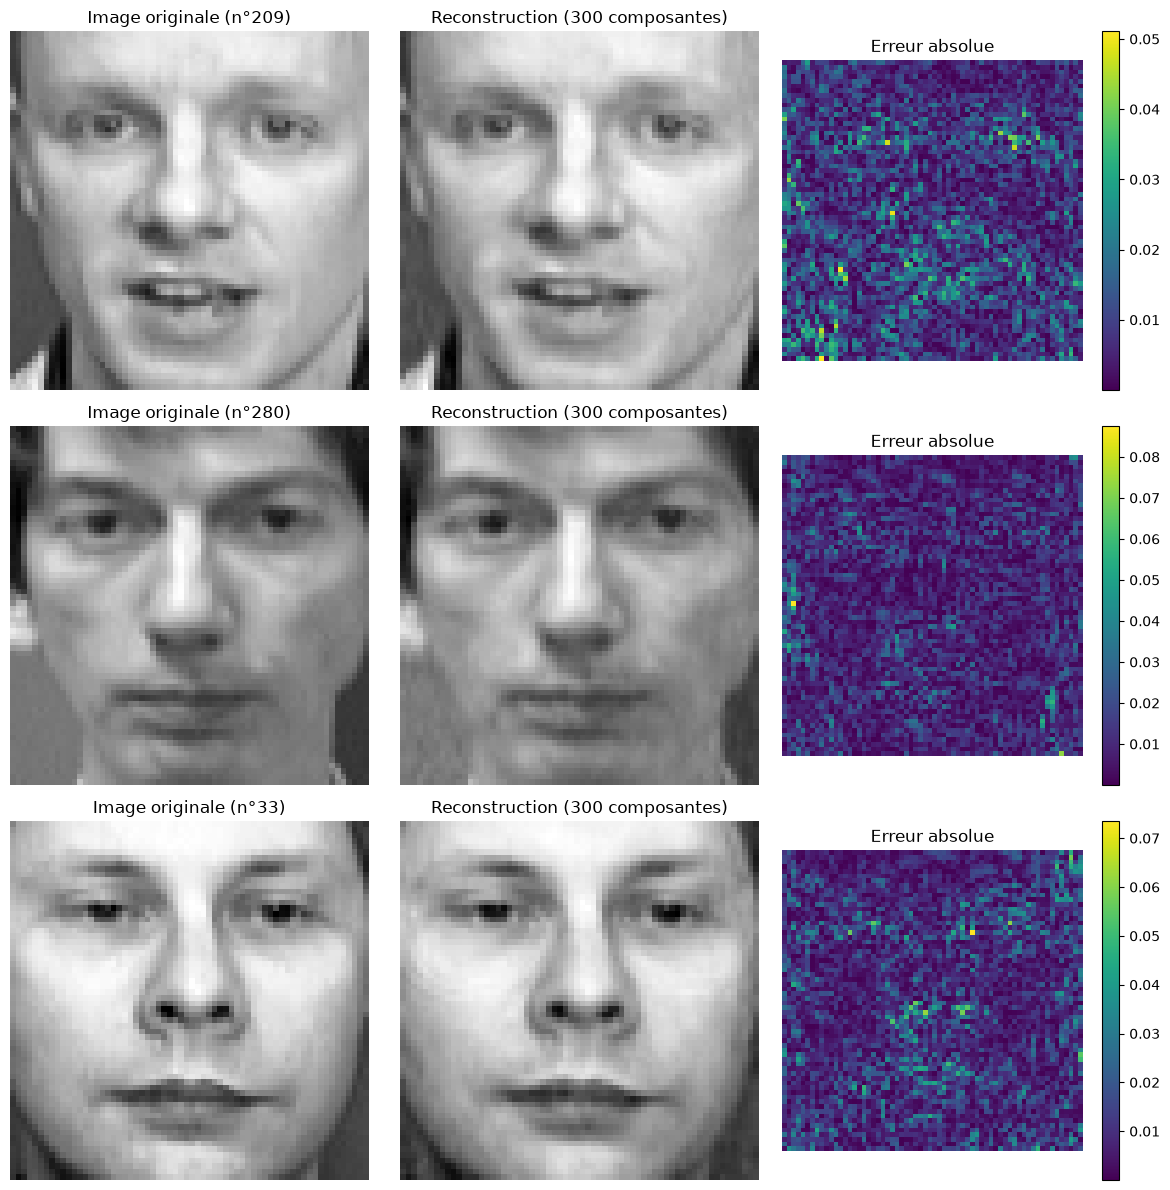

In [14]:
# PCA
pca = PCA(n_components=300)
pca.fit(X)

# reconstruction de N images tirées au hasard
N = 3
np.random.seed(42)
idx = np.random.choice(X.shape[0], N, replace=False)
images = X[idx]
images_latentes = pca.transform(images)
images_rec = pca.inverse_transform(images_latentes)

fig, ax = plt.subplots(N, 3, figsize=(12, 4*N))

for k in range(N):
    ax[k, 0].imshow(images[k].reshape(64, 64), cmap='gray')
    ax[k, 0].set_title("Image originale (n°{})".format(idx[k]))

    ax[k, 1].imshow(images_rec[k].reshape(64, 64), cmap='gray')
    ax[k, 1].set_title("Reconstruction (300 composantes)")

    im = ax[k, 2].imshow(np.abs(images[k] - images_rec[k]).reshape(64, 64))
    ax[k, 2].set_title("Erreur absolue")
    fig.colorbar(im, ax=ax[k, 2])

for a in ax.flat:
    a.axis('off')
plt.tight_layout()
plt.show()

In [15]:
# métriques de qualité de la reconstruction

from skimage.metrics import structural_similarity as ssim

for k in range(N):
    # MSE pixel par pixel
    mse = np.mean((images[k] - images_rec[k]) ** 2)

    # SSIM
    s = ssim(images[k].reshape(64, 64), images_rec[k].reshape(64, 64), data_range=1)

    print("Image n°{} - MSE : {:.2e}, SSIM : {:.4f}".format(idx[k], mse, s))

Image n°209 - MSE : 1.50e-04, SSIM : 0.9794
Image n°280 - MSE : 1.78e-04, SSIM : 0.9673
Image n°33 - MSE : 2.02e-04, SSIM : 0.9763


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On garde 300 composantes, qui expliquent environ 99.4% de la variance. On compare plusieurs images tirées au hasard à leur reconstruction. (note : pour la reconstruction, on utilise `.inverse_transform` qui s'occupe de projeter sur l'espace originale de dimension 4096 ainsi que <b>d'ajouter la moyenne des images</b>).

D'un point de vue visuel, pour chaque image, l'originale et sa reconstruction sont très ressemblantes et on n'arrive pas à disciner laquelle est la vraie.
L'affichage de l'erreur absolue (pixel par pixel) nous permet d'identifier les zones précises où l'erreur est la plus grande. C'est souvent des petites zones qui ne sont pas déterminantes dans la "compréhension" du visage (ses caractéristiques qui lui définissent).

Pour les métriques, on utilise la MSE pixel par pixel, qui n'est pas très parlante en tant que telle, d'autant plus qu'elle compare les pixels terme à terme (donc un même MSE peut être obtenue soit avec une image très floue soit avec une image où seulement un détail n'est pas bon). Après quelques recherches, on se penche sur la similarité structurelle (SSIM, https://fr.wikipedia.org/wiki/Structural_Similarity) qui vise à détecter une différence de "structure" entre 2 images, ce qui est plus proche de comment l'oeil humain analyse une image.

On utilise l'implémentation de scikit-image (https://scikit-image.org/docs/0.25.x/auto_examples/transform/plot_ssim.html) qui consiste à faire le même calcul sur plusieurs fenêtres de l'image. Sur chaque fenêtre, on calcule entre $x$ et $y$ (fenêtres de l'image A et l'image B à comparer):

$$SSIM(x,y) = l(x,y)\cdot c(x,y)\cdot s(x,y)$$

avec $l$ qui compare la luminance, $c$ le contraste et $s$ la structure (corrélation).

On obtient une SSIM d'environ 0.97, ce qui est considéré comme très bon dans la littérature pour une compression d'image.

On peut descendre jusqu'à seulement 100 composantes pour maintenir un SSIM de 0.90.
</div>

**Q6.** For the same image, display with subplots how the reconstruction evolves while keeping only 10, 20, 30... Up to 300 components.

What is the minimal number of components for which you consider the reconstruction to be acceptable ?

Conclude about the usefulness of this method.

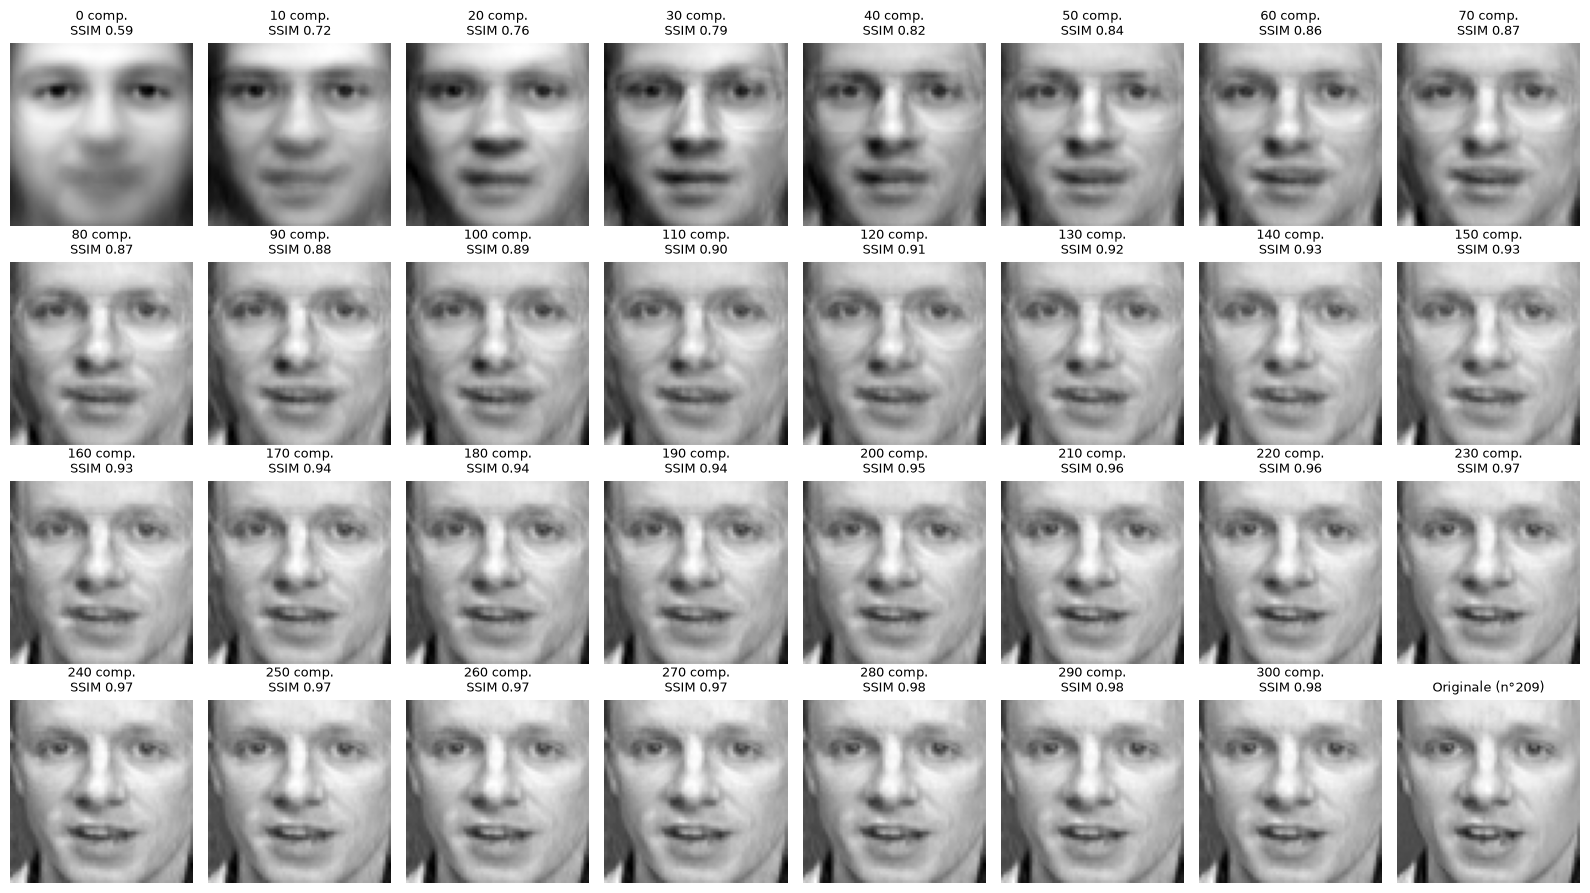

In [16]:
image = images[0]
coeffs_latent = pca.transform(image.reshape(1, -1))[0] # (300,) = une coordonnée par composante

n_composantes = np.arange(0, 301, 10)

fig, ax = plt.subplots(4, 8, figsize=(16, 9))
ax = ax.flat

for j, n_c in enumerate(n_composantes):
    # image_rec = image moyenne + coeffs_latent[0] * composante_0 + ... + coeffs_latent[n-1] * composante_(n-1)
    # l'image reconstruite est donc une combinaison linéaire de toutes les eigenfaces (+moyenne)
    image_rec = pca.mean_ + coeffs_latent[:n_c] @ pca.components_[:n_c]
    s = ssim(image.reshape(64, 64), image_rec.reshape(64, 64), data_range=1) # calcul de la métrique

    ax[j].imshow(image_rec.reshape(64, 64), cmap='gray')
    ax[j].set_title("{} comp.\nSSIM {:.2f}".format(n_c, s), fontsize=9)

# on place en derniere image l'image originale
ax[-1].imshow(image.reshape(64, 64), cmap='gray')
ax[-1].set_title("Originale (n°{})".format(idx[0]), fontsize=9)

for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
La reconstruction consiste à ajouter, à partir de l'image moyenne, l'eigenface correspondant à la composante 1, puis 2 etc, chacune pondérée par le coefficient obtenue dans la projection PCA de l'image. Cela revient à exprimer l'image dans la base des 300 composantes trouvées par PCA, en prenant de plus en plus de composantes.
Avec 300 composantes, on retrouve le même résultat que `.inverse_transform` en Q5 (qui fait la même procédure).

On voit qu'en ajoutant la composante 0 (la moyenne), on récupère les caractéristiques communes de tous les visages : forme des yeux, nez et bouche.
Ensuite, les premières composantes reconstruisent les caractéristiques du visage en question (les caractéristiques qui varient le plus entre les visages : exposition, cadrage, placement du nez etc). Par exemple, entre la composante 30 et 50, on arrive à bien reconstruire les sourcils. Il faut la composante 90 pour bien définir les dents. Les composantes suivantes sont beaucoup plus fines et il est difficile de leur attribuer un comportement macroscopique.

A l'oeil nu, on estime que l'image est fidèle à partir de 200 composantes environ, soit un SSIM de 0.95.

Conclusion : on arrive assez facilement à réduire la dimension d'une image, de 4096 attributs à seulement 200 attributs.
Comme on l'a vu, cela peut être utile pour réduire la taille des données d'entraînement et donc augmenter sa vitesse, mais aussi cela peut apporter une certaine régularisation/un débruitage.
</div>